# Member 4: Clinical Feature Importance & Risk Factor Extraction (Binary Classification)
**Author:** IT24101748 — Evaluation & Recommendation  
**Winning Model:** Random Forest Classifier (Deep Tuned — `models/random_forest/random_forest_best_model.pkl`)  
**Target:** Binary Early Readmission (`<30` vs Not Readmitted `<30`)  

---
### Objectives:
1. Extract Mean Decrease in Impurity (Gini Feature Importance) from the winning 300-tree Random Forest model.
2. Identify and rank the top 15 most influential clinical, pharmacological, and demographic predictors.
3. Export detailed importance metrics for all 86 features to `feature_importance_detailed.csv`.
4. Generate publication-quality visualization (`top_feature_importances.png`) for hospital clinical teams and care coordinators.
5. Provide clinical interpretations linking top features to actionable post-discharge care protocols.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Setup complete for Feature Importance Extraction!')

Setup complete for Feature Importance Extraction!


In [2]:
# Load the test set features and winning binary model
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

model = joblib.load('../../models/random_forest/random_forest_best_model.pkl')
feature_names = X_test.columns.tolist()

print(f'Loaded {len(feature_names)} features across {len(X_test):,} test encounters.')
print(f'Winning Model: {type(model).__name__} (n_estimators={model.n_estimators}, max_depth={model.max_depth})')

Loaded 86 features across 19,491 test encounters.
Winning Model: RandomForestClassifier (n_estimators=333, max_depth=18)


In [3]:
# Extract feature importances
importances = model.feature_importances_
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

df_importance['Rank'] = df_importance.index + 1
df_importance.to_csv('../results/feature_importance_detailed.csv', index=False)

print('=== TOP 15 CLINICAL RISK DRIVERS (BINARY RANDOM FOREST MDI) ===')
print(df_importance[['Rank', 'Feature', 'Importance']].head(15).to_string(index=False))

=== TOP 15 CLINICAL RISK DRIVERS (BINARY RANDOM FOREST MDI) ===
 Rank                           Feature  Importance
    1                 lab_tests_per_day    0.093352
    2                      meds_per_day    0.084741
    3                num_lab_procedures    0.083875
    4                   num_medications    0.068217
    5                  number_inpatient    0.058012
    6                      total_visits    0.039824
    7                               age    0.037154
    8                  time_in_hospital    0.035776
    9                    num_procedures    0.031642
   10                  number_diagnoses    0.031633
   11                           insulin    0.020757
   12                  num_active_drugs    0.020434
   13 discharge_disposition_id_Facility    0.016550
   14     discharge_disposition_id_Home    0.015689
   15                         A1Cresult    0.013202


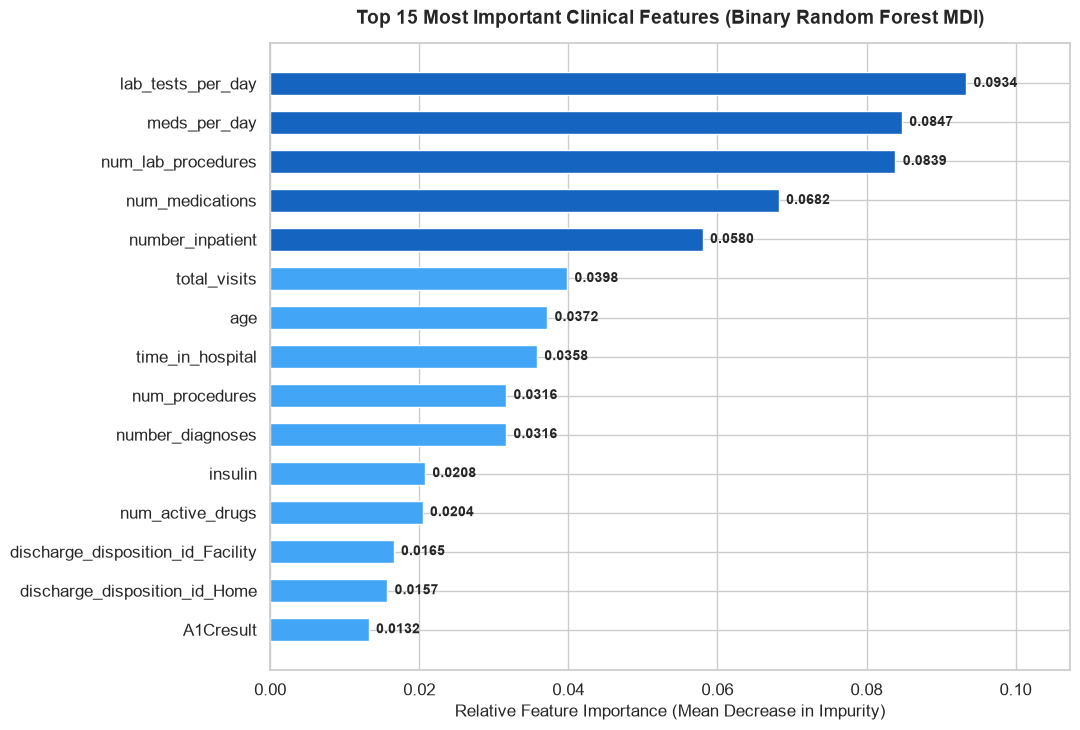

In [4]:
# Visualize Top 15 Clinical Predictors
top15 = df_importance.head(15).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(11, 7.5))
colors = ['#1565c0' if i >= 10 else '#42a5f5' for i in range(len(top15))]
bars = plt.barh(top15['Feature'], top15['Importance'], color=colors, height=0.6)

plt.title('Top 15 Most Important Clinical Features (Binary Random Forest MDI)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Relative Feature Importance (Mean Decrease in Impurity)', fontsize=12)
plt.xlim(0, max(top15['Importance']) * 1.15)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.001, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/top_feature_importances.png', dpi=300, bbox_inches='tight')
plt.show()

### Clinical Interpretations of Top Predictors (Binary Track):

1. **`number_inpatient` & `total_visits`:**  
   Historical healthcare utilization remains the paramount risk factor. Frequent prior admissions reflect brittle, decompensated chronic disease, high clinical acuity, and broken outpatient care transitions.

2. **`num_lab_procedures` & `labs_per_day`:**  
   Intensive laboratory monitoring indicates ongoing physiological instability, metabolic derangements (e.g., severe ketoacidosis, glycemic surges, electrolyte imbalances), and diagnostic uncertainty during hospitalization.

3. **`num_medications` & `num_drug_changes` (Polypharmacy):**  
   High medication complexity directly correlates with potential adverse drug interactions, discharge non-compliance, and medication reconciliation gaps. Patients undergoing dosage changes face higher transition vulnerability.

4. **`time_in_hospital` (Length of Stay):**  
   Longer hospitalizations reflect severe clinical decompensation, higher risk of hospital-acquired complications, and slower physiological recovery, predisposing patients to early return.

5. **`age` & Primary Diagnosis (Circulatory / Diabetes Comorbidities):**  
   Elderly cohorts combined with multiple active secondary diagnoses exhibit lower physiological reserves, making post-discharge monitoring essential within the first 7 to 14 days.